## Batch Gradient Descent v/s Stochastic Gradient Descent v/s Mini Batch Gradient Descent

**Batch Gradient Descent** -> We go through all training samples in each iteration and calculate cumulative error for one forward pass and then adjust weights

**Stochastic Gradient Descent** -> We go through one (randomly picked) training samples in each iteration and calculate cumulative error for one forward pass and then adjust weights

**Mini Batch Gradient Descent** -> We go through a batch of randomly picked training samples in each iteration and calculate cumulative error for one forward pass and then adjust weights

### Explanation with code

In [7]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

In [8]:
df = pd.read_csv("homeprices_banglore.csv")
df.head()

,area,bedrooms,price
0,1056,2,39.07
1,2600,4,120.00
2,1440,3,62.00
3,1521,3,75.00
4,1200,2,51.00


#### Performing Scaling
-- With MinMaxScaler() -> This scaling brings data to 0 - 1

In [9]:
from sklearn import preprocessing

sx = preprocessing.MinMaxScaler() # Area, Bedrooms
sy = preprocessing.MinMaxScaler() # Price

In [10]:
scaled_X = sx.fit_transform(df.drop('price',axis='columns'))
scaled_X

array([[0.08827586, 0.25      ],
       [0.62068966, 0.75      ],
       [0.22068966, 0.5       ],
       [0.24862069, 0.5       ],
       [0.13793103, 0.25      ],
       [0.12758621, 0.25      ],
       [0.6662069 , 0.75      ],
       [0.86206897, 0.75      ],
       [0.17586207, 0.5       ],
       [1.        , 1.        ],
       [0.34482759, 0.5       ],
       [0.68448276, 0.75      ],
       [0.06896552, 0.25      ],
       [0.10344828, 0.25      ],
       [0.5       , 0.5       ],
       [0.12931034, 0.25      ],
       [0.13103448, 0.5       ],
       [0.25517241, 0.5       ],
       [0.67931034, 0.5       ],
       [0.        , 0.        ]])

In [11]:
scaled_Y = sy.fit_transform(df['price'].values.reshape(df.shape[0],1))
scaled_Y

array([[0.05237037],
       [0.65185185],
       [0.22222222],
       [0.31851852],
       [0.14074074],
       [0.04444444],
       [0.76296296],
       [0.91111111],
       [0.13333333],
       [1.        ],
       [0.37037037],
       [0.8       ],
       [0.04444444],
       [0.05925926],
       [0.51111111],
       [0.07407407],
       [0.11851852],
       [0.20740741],
       [0.51851852],
       [0.        ]])

### Batch Gradient Descent
-- Find w1, w2 and bias

In [12]:
w = np.ones(shape=(2))
w

array([1., 1.])

In [13]:
np.dot(w, scaled_X.T) # Dot product , T-Transpose

array([0.33827586, 1.37068966, 0.72068966, 0.74862069, 0.38793103,
       0.37758621, 1.4162069 , 1.61206897, 0.67586207, 2.        ,
       0.84482759, 1.43448276, 0.31896552, 0.35344828, 1.        ,
       0.37931034, 0.63103448, 0.75517241, 1.17931034, 0.        ])

In [14]:
def batch_gradient_descent(X, y_true, epochs, learning_rate = 0.01):
    number_of_features = X.shape[1]

    w = np.ones(shape=(number_of_features)) # ([1. , 1.])
    b = 0
    total_samples = X.shape[0]

    cost_list = []
    epoch_list = []

    for i in range(epochs):
        y_predicted = np.dot(w, scaled_X.T) + b

        # derivatives
        w_grad = -(2/total_samples)*(X.T.dot(y_true-y_predicted))
        b_grad = -(2/total_samples)*np.sum(y_true-y_predicted)

        w = w - learning_rate * w_grad
        b = b - learning_rate * b_grad

        cost = np.mean(np.square(y_true-y_predicted))

        if i%10==0:  # at every 10th iteration record the cost and epoch value
            cost_list.append(cost)
            epoch_list.append(i)
    return w, b, cost, cost_list, epoch_list

w, b, cost , cost_list, epoch_list = batch_gradient_descent(scaled_X, scaled_Y.reshape(scaled_Y.shape[0],),500)
w, b, cost         
            

(array([0.70712464, 0.67456527]),
 np.float64(-0.23034857438407422),
 np.float64(0.0068641890429808105))

In [15]:
# above output format : ([w1, w2], bias, cost)

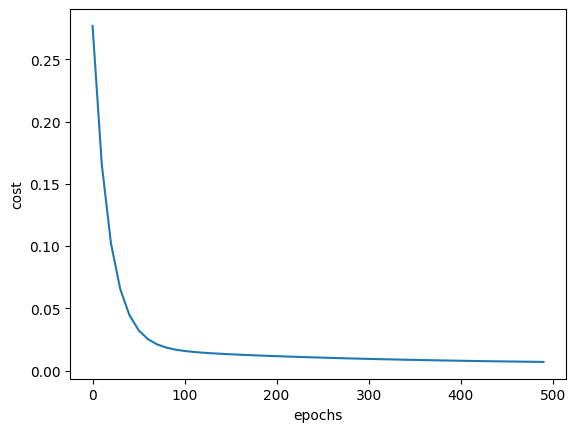

In [16]:
plt.xlabel('epochs')
plt.ylabel('cost')
plt.plot(epoch_list, cost_list)

 **Now, the formula satisfy**
 
  price = w1 * area + w2 * bedrooms + bias
  
  *[This is the prediction formula]*

  ##### The Linear Regression Model do the same (find w1, w2 and bias)

In [17]:
# prediction function 

def predict(area, bedrooms, w, b):
    scaled_X = sx.transform([[area, bedrooms]])[0] # Scaling 
    
    scaled_price = w[0] * scaled_X[0] + w[1] * scaled_X[1] + b
    return sy.inverse_transform([[scaled_price]])[0] # Inverse scaling to get original value

In [18]:
predict(2600, 4, w, b)

C:\Users\rosha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


array([128.45484403])

In [19]:
predict(1500,3,w,b)

C:\Users\rosha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


array([69.47860786])

### Stochastic Gradient Descent
-- Find w1, w2 and bias

In [20]:
import random

def stochastic_gradient_descent(X, y_true, epochs, learning_rate=0.01):
    number_of_features = X.shape[1]
    # number array with 1 row and columns equal to number of features.
    # In our case number_of_features = 3 (equal, bedroom and age)
    w = np.ones(shape=(number_of_features))
    b= 0 
    total_samples = X.shape[0]

    cost_list = []
    epoch_list = []

    for i in range(epochs):
        random_index = random.randint(0, total_samples-1)
        sample_x = X[random_index]
        sample_y = y_true[random_index]
        y_predicted = np.dot(w, sample_x.T) + b

         # derivatives
        w_grad = -(2/total_samples)*(sample_x.T.dot(sample_y-y_predicted))
        b_grad = -(2/total_samples)*(sample_y-y_predicted)

        w = w - learning_rate * w_grad
        b = b - learning_rate * b_grad

        cost = np.square(sample_y-y_predicted)

        if i%100==0: # at every 100th iteration record the cost and epoch value
            cost_list.append(cost)
            epoch_list.append(i)
    return w, b, cost, cost_list, epoch_list
   

In [21]:
w_sgd, b_sgd, cost_sgd, cost_list_sgd, epoch_list_sgd = stochastic_gradient_descent(scaled_X,scaled_Y.reshape(scaled_Y.shape[0],),10000)
w_sgd, b_sgd, cost_sgd                                                                                   

(array([0.70530972, 0.67523804]),
 np.float64(-0.229045492963253),
 np.float64(0.052566919118096654))

In [22]:
# above output format : ([w1, w2], bias, cost)

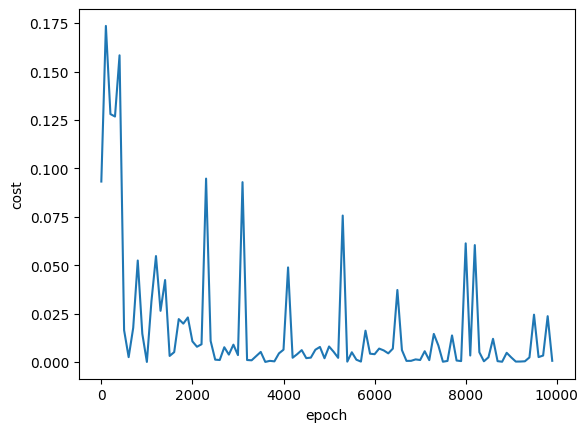

In [23]:
plt.xlabel("epoch")
plt.ylabel("cost")
plt.plot(epoch_list_sgd, cost_list_sgd)

In [25]:
predict(2600,4,w_sgd,b_sgd)

C:\Users\rosha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


array([128.54679981])

In [28]:
def mini_batch_gradient_descent(X, y_true, epochs, learning_rate=0.01, batch_size=32):
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0
    losses = []

    for epoch in range(epochs):
        # Shuffle the dataset at the start of each epoch
        indices = np.arange(n_samples)
        np.random.shuffle(indices)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Predictions
            y_pred = np.dot(X_batch, weights) + bias

            # Compute gradients
            error = y_pred - y_batch
            dw = (1 / batch_size) * np.dot(X_batch.T, error)
            db = (1 / batch_size) * np.sum(error)

            # Update parameters
            weights -= learning_rate * dw
            bias -= learning_rate * db

        # Compute loss for monitoring (MSE)
        y_pred_full = np.dot(X, weights) + bias
        loss = np.mean((y_pred_full - y) ** 2)
        losses.append(loss)

        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}")

    return weights, bias, losses


In [29]:
w_mbs, b_mbs, cost_mbs, cost_list_mbs, epoch_list_mbs = stochastic_gradient_descent(scaled_X,scaled_Y.reshape(scaled_Y.shape[0],),10000)
w_mbs, b_mbs, cost_mbs                                                                                 

(array([0.70734098, 0.67473167]),
 np.float64(-0.23184352164907615),
 np.float64(0.006195630669440449))

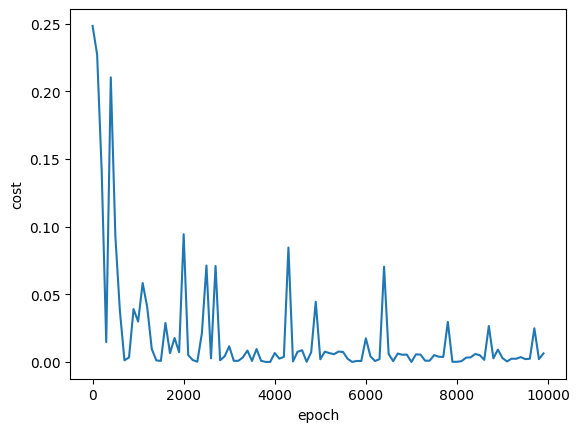

In [30]:
plt.xlabel("epoch")
plt.ylabel("cost")
plt.plot(epoch_list_mbs, cost_list_mbs)

In [31]:
predict(2600,4,w_mbs,b_mbs)

C:\Users\rosha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


array([128.28800242])